# Protein-function DMS mechanism check

## 1. Data acquisition

ProteinGym v1.3 supplies human deep mutational scanning measurements, assay metadata and AlphaFold structures. The metadata revision and all file hashes are specified below. UniProt canonical protein sequences were retrieved November 9, 2026. AlphaMissense uses its released substitution scores; no model is trained or fine-tuned.


In [1]:
from pathlib import Path
from collections import Counter,defaultdict
from io import BytesIO
import os,sys,json,gzip,csv,re,hashlib,time,urllib.request,ssl,zipfile,math,platform
for key in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']:os.environ[key]='1'
import numpy as np
import pandas as pd
from scipy.stats import spearmanr,wilcoxon
from sklearn.metrics import roc_auc_score,average_precision_score
from Bio.Align import substitution_matrices
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display,Image,Markdown
RAW=Path(os.environ.get('AM_RAW_INPUTS','am_public_inputs')).expanduser().resolve()
OUTPUT=Path('calculated_outputs').resolve();RAW.mkdir(parents=True,exist_ok=True);OUTPUT.mkdir(parents=True,exist_ok=True)
STARTED=time.time()
pd.set_option('display.max_colwidth',100)
def show_figure(fig):
    buffer=BytesIO();fig.savefig(buffer,format='png',dpi=150,bbox_inches='tight');display(Image(data=buffer.getvalue()))


In [2]:
SOURCES = [{'id': 'am_hg38',
  'path': 'inputs/raw/AlphaMissense_hg38.tsv.gz',
  'url': 'https://storage.googleapis.com/dm_alphamissense/AlphaMissense_hg38.tsv.gz',
  'sha256': '0516cfd71c0767ac8f9c469252d429000e94e02c008b6e3a46d4b4646fcd3475',
  'bytes': 642961469},
 {'id': 'am_aa',
  'path': 'inputs/raw/AlphaMissense_aa_substitutions.tsv.gz',
  'url': 'https://storage.googleapis.com/dm_alphamissense/AlphaMissense_aa_substitutions.tsv.gz',
  'sha256': 'bc18d954a9aa6b9efab8e40d6d1912e32b774906cd3846a1f51066588e9c176d',
  'bytes': 1207278510},
 {'id': 'gencode32',
  'path': 'inputs/raw/gencode.v32.annotation.gtf.gz',
  'url': 'https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_32/gencode.v32.annotation.gtf.gz',
  'sha256': 'da9dc827e9a111c9bde60c55f55b7d37ffebc4649fc01f0745a670240e939ed4',
  'bytes': 43097815},
 {'id': 'proteingym_dms',
  'path': 'inputs/raw/DMS_ProteinGym_v1.3_substitutions.zip',
  'url': 'https://marks.hms.harvard.edu/proteingym/ProteinGym_v1.3/DMS_ProteinGym_substitutions.zip',
  'sha256': '3a83766254ac9ac9984ec25cb73c6e010ea4418f5e35f143933e6b6e6473b921',
  'bytes': 43021128},
 {'id': 'proteingym_af2',
  'path': 'inputs/raw/ProteinGym_v1.3_AF2_structures.zip',
  'url': 'https://marks.hms.harvard.edu/proteingym/ProteinGym_v1.3/ProteinGym_AF2_structures.zip',
  'sha256': 'ed8611bf12cfb840ea1c2561be36254901008610a49b1be475e917b6c5d6d56a',
  'bytes': 19173248},
 {'id': 'proteingym_metadata',
  'path': 'inputs/raw/DMS_substitutions.csv',
  'url': 'https://raw.githubusercontent.com/OATML-Markslab/ProteinGym/144fe22b07dfaeec2b366f2346203a9838a55b4c/reference_files/DMS_substitutions.csv',
  'sha256': 'a8f498011532a74aa9fe556a50555a75e928c5837d19c06a87592ae04049b308',
  'bytes': None},
 {'id': 'uniprot_human',
  'path': 'uniprot_reviewed_human_20261109.fasta.gz',
  'url': 'https://rest.uniprot.org/uniprotkb/stream?query=%28proteome%3AUP000005640%29%20AND%20%28reviewed%3Atrue%29&format=fasta&compressed=true',
  'sha256': '97e06262e2679f9541d1b10245f480f1cd82e00a79e2c99db032e6669dd5b48d',
  'bytes': 7505116}]

def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
def acquire(source):
    p=RAW/Path(source['path']).name
    if not p.exists():
        partial=p.with_name(p.name+'.notebook-part')
        req=urllib.request.Request(source['url'],headers={'User-Agent':'AlphaMissense-analysis/1.0'})
        # ProteinGym's server omits an intermediate certificate; exact archive
        # content is authenticated by the fixed SHA256 below.
        context=ssl._create_unverified_context() if 'marks.hms.harvard.edu' in source['url'] and source.get('sha256') else None
        with urllib.request.urlopen(req,timeout=180,context=context) as r,partial.open('wb') as f:
            while True:
                b=r.read(4*1024*1024)
                if not b:break
                f.write(b)
        if source.get('sha256') and sha256_file(partial)!=source['sha256']:raise ValueError('Download checksum mismatch: '+p.name)
        if source.get('bytes') and partial.stat().st_size!=source['bytes']:raise ValueError('Download size mismatch: '+p.name)
        partial.replace(p)
    h=sha256_file(p)
    if source.get('sha256') and h!=source['sha256']:raise ValueError('Input checksum mismatch: '+p.name)
    if source.get('bytes') and p.stat().st_size!=source['bytes']:raise ValueError('Input size mismatch: '+p.name)
    return dict(path=p.name,url=source['url'],sha256=h,bytes=p.stat().st_size)
source_receipts=[acquire(s) for s in SOURCES]
display(pd.DataFrame(source_receipts))


,path,url,sha256,bytes
0,AlphaMissense_hg38.tsv.gz,https://storage.googleapis.com/dm_alphamissense/AlphaMissense_hg38.tsv.gz,0516cfd71c0767ac8f9c469252d429000e94e02c008b6e3a46d4b4646fcd3475,642961469
1,AlphaMissense_aa_substitutions.tsv.gz,https://storage.googleapis.com/dm_alphamissense/AlphaMissense_aa_substitutions.tsv.gz,bc18d954a9aa6b9efab8e40d6d1912e32b774906cd3846a1f51066588e9c176d,1207278510
2,gencode.v32.annotation.gtf.gz,https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_32/gencode.v32.annotation.gtf.gz,da9dc827e9a111c9bde60c55f55b7d37ffebc4649fc01f0745a670240e939ed4,43097815
3,DMS_ProteinGym_v1.3_substitutions.zip,https://marks.hms.harvard.edu/proteingym/ProteinGym_v1.3/DMS_ProteinGym_substitutions.zip,3a83766254ac9ac9984ec25cb73c6e010ea4418f5e35f143933e6b6e6473b921,43021128
4,ProteinGym_v1.3_AF2_structures.zip,https://marks.hms.harvard.edu/proteingym/ProteinGym_v1.3/ProteinGym_AF2_structures.zip,ed8611bf12cfb840ea1c2561be36254901008610a49b1be475e917b6c5d6d56a,19173248
5,DMS_substitutions.csv,https://raw.githubusercontent.com/OATML-Markslab/ProteinGym/144fe22b07dfaeec2b366f2346203a9838a5...,a8f498011532a74aa9fe556a50555a75e928c5837d19c06a87592ae04049b308,208734
6,uniprot_reviewed_human_20261109.fasta.gz,https://rest.uniprot.org/uniprotkb/stream?query=%28proteome%3AUP000005640%29%20AND%20%28reviewed...,97e06262e2679f9541d1b10245f480f1cd82e00a79e2c99db032e6669dd5b48d,7505116


## 2. Raw processing

Read each human assay directly from the public archive. Retain standard single substitutions outside the start position, validate the wild-type residue, map entry names to reviewed human UniProt records, map each local assay position to the reviewed UniProt sequence by exact substring or matching-residue local alignment (match 2, mismatch −1, gap open −10, extension −0.5), and require an unambiguous AlphaMissense score. Unmapped or conflicting records are counted and excluded. Protein partitions are determined from the first 32 bits of SHA256 of `spectra-alphamissense-dms-v1|` plus the entry name, modulo 10; values 0–3 form discovery.


In [3]:
# Public canonical sequence records provide an accession/entry-name map.
entry_accessions=defaultdict(list);canonical={};acc=None;buf=[]
with gzip.open(RAW/'uniprot_reviewed_human_20261109.fasta.gz','rt') as f:
    for line in f:
        line=line.strip()
        if line.startswith('>'):
            if acc:canonical[acc]=''.join(buf)
            fields=line.split()[0].split('|');acc=fields[1];entry_accessions[fields[2]].append(acc);buf=[]
        else:buf.append(line)
    if acc:canonical[acc]=''.join(buf)
AA_RE=re.compile(r'^([ACDEFGHIKLMNPQRSTVWY])(\d+)([ACDEFGHIKLMNPQRSTVWY])$')
def protein_split(entry: str) -> str:
    value = int.from_bytes(hashlib.sha256(
        ("spectra-alphamissense-dms-v1|" + entry).encode()).digest()[:4], "big") % 10
    return "discovery" if value < 4 else "confirmation"

def load_dms_rows() -> tuple[pd.DataFrame, dict, Counter]:
    ref = pd.read_csv(RAW / "DMS_substitutions.csv")
    ref = ref[ref.taxon.eq("Human")].copy()
    candidates = dict(entry_accessions)
    qc = Counter()
    rows = []
    archive = RAW / "DMS_ProteinGym_v1.3_substitutions.zip"
    with zipfile.ZipFile(archive) as zf:
        for _, meta in ref.iterrows():
            if meta.UniProt_ID not in candidates:
                qc["assays_without_canonical_accession"] += 1
                continue
            name = f"DMS_ProteinGym_substitutions/{meta.DMS_filename}"
            with zf.open(name) as handle:
                assay = pd.read_csv(handle)
            for record in assay.itertuples(index=False):
                qc["dms_rows_scanned"] += 1
                mutant = str(record.mutant)
                match = AA_RE.match(mutant)
                if not match:
                    qc["excluded_non_single_or_noncanonical_mutant"] += 1
                    continue
                ref_aa, pos_text, alt_aa = match.groups()
                pos = int(pos_text)
                if pos == 1:
                    qc["excluded_start_loss_position1"] += 1
                    continue
                target = str(meta.target_seq)
                if pos > len(target) or target[pos - 1] != ref_aa:
                    qc["excluded_proteingym_reference_mismatch"] += 1
                    continue
                rows.append({
                    "dms_id": meta.DMS_id, "entry_name": meta.UniProt_ID,
                    "protein_partition": protein_split(meta.UniProt_ID),
                    "mutant": mutant, "ref_aa": ref_aa, "aa_pos": pos, "alt_aa": alt_aa,
                    "dms_score": float(record.DMS_score),
                    "dms_score_bin": int(record.DMS_score_bin),
                    "dms_deleterious": 1 - int(record.DMS_score_bin),
                    "selection_type": meta.selection_type,
                    "coarse_selection_type": meta.coarse_selection_type,
                    "msa_neff_l": meta.MSA_Neff_L, "msa_depth_category": meta.MSA_Neff_L_category,
                    "protein_length": len(target),
                })
    df = pd.DataFrame(rows)
    qc["eligible_human_single_mutant_rows"] = len(df)
    qc["human_assays"] = df.dms_id.nunique()
    qc["human_proteins"] = df.entry_name.nunique()
    return df, candidates, qc

def score_keys(df: pd.DataFrame, candidates: dict) -> tuple[dict, Counter]:
    wanted = set()
    for entry, mutant in df[["entry_name", "mutant"]].drop_duplicates().itertuples(index=False):
        for accession in candidates.get(entry, []):
            wanted.add((accession, mutant))
    found = defaultdict(list)
    qc = Counter()
    with gzip.open(RAW / "AlphaMissense_aa_substitutions.tsv.gz", "rt", newline="") as handle:
        reader = csv.reader(handle, delimiter="\t")
        for f in reader:
            if not f or f[0].startswith("#") or f[0] == "uniprot_id":
                continue
            qc["aa_score_rows_scanned"] += 1
            key = (f[0], f[1])
            if key in wanted:
                found[key].append((float(f[2]), f[3]))
    qc["wanted_accession_mutation_keys"] = len(wanted)
    qc["matched_accession_mutation_keys"] = len(found)
    return found, qc

def resolve_scores(df: pd.DataFrame, candidates: dict, found: dict, qc: Counter) -> pd.DataFrame:
    accessions, scores, classes = [], [], []
    for entry, mutant in df[["entry_name", "mutant"]].itertuples(index=False):
        options = []
        for accession in candidates.get(entry, []):
            for score, cls in found.get((accession, mutant), []):
                options.append((accession, score, cls))
        unique = {(round(x[1], 8), x[2]) for x in options}
        if not options:
            accessions.append(None); scores.append(np.nan); classes.append(None)
            continue
        if len(unique) > 1:
            qc["ambiguous_accession_score_rows"] += 1
            accessions.append(None); scores.append(np.nan); classes.append(None)
            continue
        accessions.append("|".join(sorted({x[0] for x in options})))
        scores.append(options[0][1]); classes.append(options[0][2])
    out = df.copy()
    out["uniprot_accession"] = accessions
    out["am_pathogenicity"] = scores
    out["am_class"] = classes
    qc["dms_rows_with_am_score"] = int(out.am_pathogenicity.notna().sum())
    return out[out.am_pathogenicity.notna()].copy()

from Bio.Align import PairwiseAligner
metadata=pd.read_csv(RAW/'DMS_substitutions.csv').set_index('DMS_id')
def residue_map(query,reference):
    offset=reference.find(query)
    if offset>=0:return {i+1:i+1+offset for i in range(len(query))},'exact substring'
    aligner=PairwiseAligner();aligner.mode='local';aligner.match_score=2;aligner.mismatch_score=-1;aligner.open_gap_score=-10;aligner.extend_gap_score=-.5
    alignment=aligner.align(reference,query)[0];mapping={}
    for (ra,rb),(qa,qb) in zip(*alignment.aligned):
        for r,q in zip(range(ra,rb),range(qa,qb)):
            if reference[r]==query[q]:mapping[q+1]=r+1
    return mapping,'local alignment, matching residues only'
df,candidates,qc=load_dms_rows()
accessions={a for entry in df.entry_name.unique() for a in candidates.get(entry,[])}
released=defaultdict(dict);ambiguous_scores=set()
with gzip.open(RAW/'AlphaMissense_aa_substitutions.tsv.gz','rt') as stream:
    for line in stream:
        if line.startswith('#') or line.startswith('uniprot_id'):continue
        fields=line.rstrip().split('\t')
        if fields[0] not in accessions:continue
        match=AA_RE.fullmatch(fields[1])
        if match:
            key=(match[1],int(match[2]),match[3]);value=(float(fields[2]),fields[3])
            old=released[fields[0]].get(key)
            if old is not None and old!=value:ambiguous_scores.add((fields[0],key))
            released[fields[0]][key]=value
qc['conflicting released substitution keys']=len(ambiguous_scores)
position_maps={};map_qc=[]
for aid,g in df.groupby('dms_id'):
    query=str(metadata.loc[aid,'target_seq']);entry=g.entry_name.iloc[0]
    for accession in candidates.get(entry,[]):
        reference=canonical.get(accession,'')
        if not reference:continue
        mapping,method=residue_map(query,reference);position_maps[aid,accession]=mapping
        map_qc.append({'assay':aid,'accession':accession,'target_length':len(query),'canonical_length':len(reference),'mapped_matching_positions':len(mapping),'mapping_method':method})
scored=[]
for row in df.to_dict('records'):
    choices=[]
    for accession in candidates.get(row['entry_name'],[]):
        position=position_maps.get((row['dms_id'],accession),{}).get(row['aa_pos'])
        if position is None or canonical[accession][position-1]!=row['ref_aa']:continue
        key=(row['ref_aa'],position,row['alt_aa'])
        if (accession,key) in ambiguous_scores:continue
        hit=released[accession].get(key)
        if hit:choices.append((accession,position,hit[0],hit[1]))
    signatures={(position,round(score,8),label) for _,position,score,label in choices}
    if len(signatures)!=1:
        qc['missing_or_ambiguous_canonical_score']+=1;continue
    accession,position,score,label=choices[0]
    scored.append({**row,'uniprot_accession':'|'.join(sorted({c[0] for c in choices})),'canonical_mutant':row['ref_aa']+str(position)+row['alt_aa'],'canonical_position':position,'am_pathogenicity':score,'am_class':label})
df=pd.DataFrame(scored);B62=substitution_matrices.load('BLOSUM62')
df['blosum_pathogenicity']=[-float(B62[a,b]) for a,b in zip(df.ref_aa,df.alt_aa)]
qc['DMS rows with canonical score']=len(df);mapping_qc=pd.DataFrame(map_qc);mapping_qc.to_csv(OUTPUT/'canonical_mapping.csv',index=False)
display(pd.Series(dict(qc),name='count').to_frame());display(mapping_qc)
display(df[['dms_id','entry_name','mutant','canonical_mutant','dms_score','dms_deleterious','protein_partition']].head())


,count
dms_rows_scanned,479142
excluded_non_single_or_noncanonical_mutant,156166
excluded_start_loss_position1,623
assays_without_canonical_accession,2
eligible_human_single_mutant_rows,322353
human_assays,94
human_proteins,80
conflicting released substitution keys,0
missing_or_ambiguous_canonical_score,1298
DMS rows with canonical score,321055


,assay,accession,target_length,canonical_length,mapped_matching_positions,mapping_method
0,A4_HUMAN_Seuma_2022,P05067,770,770,770,exact substring
1,ACE2_HUMAN_Chan_2020,Q9BYF1,805,805,805,exact substring
2,ADRB2_HUMAN_Jones_2020,P07550,413,413,413,exact substring
3,AICDA_HUMAN_Gajula_2014_3cycles,Q9GZX7,198,198,198,exact substring
4,AMFR_HUMAN_Tsuboyama_2023_4G3O,Q9UKV5,47,643,43,"local alignment, matching residues only"
...,...,...,...,...,...,...
89,UBE4B_HUMAN_Tsuboyama_2023_3L1X,O95155,69,1302,69,exact substring
90,UBR5_HUMAN_Tsuboyama_2023_1I2T,O95071,58,2799,58,exact substring
91,VKOR1_HUMAN_Chiasson_2020_abundance,Q9BQB6,163,163,163,exact substring
92,VKOR1_HUMAN_Chiasson_2020_activity,Q9BQB6,163,163,163,exact substring


,dms_id,entry_name,mutant,canonical_mutant,dms_score,dms_deleterious,protein_partition
0,A4_HUMAN_Seuma_2022,A4_HUMAN,A673C,A673C,-1.018869,0,discovery
1,A4_HUMAN_Seuma_2022,A4_HUMAN,A673D,A673D,-0.605052,0,discovery
2,A4_HUMAN_Seuma_2022,A4_HUMAN,A673E,A673E,-0.590857,0,discovery
3,A4_HUMAN_Seuma_2022,A4_HUMAN,A673F,A673F,-0.216833,0,discovery
4,A4_HUMAN_Seuma_2022,A4_HUMAN,A673G,A673G,0.268496,0,discovery


## 3. Axis and levels

Map each assayed substitution back to its available genomic encodings and GENCODE v32 transcripts. Require all valid encodings to agree on the internal exon-distance level. Levels are ≥50, 20–49, 3–19 and 0–2 exonic bases from an internal boundary. This protein-function measurement tests whether an apparent clinical splice-distance effect also appears without a splicing phenotype.


In [4]:
def parse_attrs(text: str) -> dict:
    out = {}
    for item in text.rstrip(";").split("; "):
        if " " in item:
            key, value = item.split(" ", 1)
            out[key] = value.strip('"')
    return out

def load_transcripts(wanted: set[str]) -> dict:
    tx = defaultdict(lambda: {"exons": [], "gene": None, "strand": None})
    with gzip.open(RAW / "gencode.v32.annotation.gtf.gz", "rt") as handle:
        for line in handle:
            if not line or line[0] == "#":
                continue
            f = line.rstrip("\n").split("\t")
            if f[2] != "exon":
                continue
            attrs = parse_attrs(f[8])
            tid = attrs.get("transcript_id")
            if tid not in wanted:
                continue
            tx[tid]["exons"].append((int(f[3]), int(f[4])))
            tx[tid]["gene"] = attrs.get("gene_name")
            tx[tid]["strand"] = f[6]
    for value in tx.values():
        value["exons"].sort()
    return dict(tx)

def splice_geometry(pos: int, exons: list[tuple[int, int]]) -> tuple[int, int, bool] | None:
    if len(exons) < 2:
        return None
    hits = []
    for i, (start, end) in enumerate(exons):
        if start <= pos <= end:
            candidates = []
            if i > 0:
                candidates.append(pos - start)
            if i < len(exons) - 1:
                candidates.append(end - pos)
            if candidates:
                hits.append((min(candidates), i + 1, i in {0, len(exons) - 1}))
    if len(hits) != 1:
        return None
    return hits[0]

def axis_level(distance: int) -> tuple[int, str]:
    if distance >= 50:
        return 0, "far"
    if distance >= 20:
        return 1, "mid"
    if distance >= 3:
        return 2, "proximal"
    return 3, "splice_region"
def genomic_mapping(df: pd.DataFrame, qc: Counter) -> pd.DataFrame:
    wanted = set()
    for acc_text, mutant in df[["uniprot_accession", "canonical_mutant"]].drop_duplicates().itertuples(index=False):
        for acc in acc_text.split("|"):
            wanted.add((acc, mutant))
    hits = defaultdict(list)
    transcripts = set()
    with gzip.open(RAW / "AlphaMissense_hg38.tsv.gz", "rt", newline="") as handle:
        reader = csv.reader(handle, delimiter="\t")
        for f in reader:
            if not f or f[0].startswith("#"):
                continue
            qc["hg38_rows_scanned_for_dms"] += 1
            key = (f[5], f[7])
            if key in wanted:
                rec = {"chrom": f[0], "pos": int(f[1]), "ref": f[2], "alt": f[3],
                       "transcript_id": f[6], "score": float(f[8])}
                hits[key].append(rec); transcripts.add(f[6])
    tx = load_transcripts(transcripts)
    geometry = defaultdict(list)
    for key, records in hits.items():
        for rec in records:
            info = tx.get(rec["transcript_id"])
            geom = splice_geometry(rec["pos"], info["exons"]) if info else None
            if geom:
                d, exon, terminal = geom
                lv, name = axis_level(d)
                geometry[key].append((lv, name, d, rec["transcript_id"], rec["chrom"], rec["pos"]))
    map_rows = []
    for (acc, mutant), values in geometry.items():
        levels = {x[0] for x in values}
        if len(levels) != 1:
            qc["excluded_dms_mutation_crossing_axis_bins"] += 1
            continue
        map_rows.append({
            "accession": acc, "canonical_mutant": mutant, "axis_level": values[0][0],
            "axis_name": values[0][1], "d_splice_bp_min": min(x[2] for x in values),
            "d_splice_bp_median": float(np.median([x[2] for x in values])),
            "genomic_encodings": len(values),
            "transcript_ids": "|".join(sorted({x[3] for x in values})),
        })
    mapping = pd.DataFrame(map_rows)
    lookup = {(r.accession, r.canonical_mutant): r for r in mapping.itertuples(index=False)}
    out_rows = []
    for r in df.itertuples(index=False):
        options = [lookup[(a, r.canonical_mutant)] for a in r.uniprot_accession.split("|")
                   if (a, r.canonical_mutant) in lookup]
        signatures = {(x.axis_level, x.d_splice_bp_min, x.d_splice_bp_median) for x in options}
        if len(signatures) != 1:
            continue
        x = options[0]
        row = r._asdict()
        row.update({"axis_level": x.axis_level, "axis_name": x.axis_name,
                    "d_splice_bp_min": x.d_splice_bp_min,
                    "d_splice_bp_median": x.d_splice_bp_median,
                    "genomic_encodings": x.genomic_encodings,
                    "transcript_ids": x.transcript_ids})
        out_rows.append(row)
    out = pd.DataFrame(out_rows)
    qc["dms_rows_with_unambiguous_genomic_axis"] = len(out)
    return out

df=genomic_mapping(df,qc)
display(df.groupby(['protein_partition','axis_level','axis_name']).agg(rows=('mutant','size'),proteins=('entry_name','nunique'),assays=('dms_id','nunique')))


rows  proteins  assays
protein_partition axis_level axis_name                             
confirmation      0          far            22530        49      55
                  1          mid            19366        47      52
                  2          proximal       11719        44      48
                  3          splice_region   2031        39      43
discovery         0          far            18631        23      31
                  1          mid            17496        24      32
                  2          proximal       10819        24      32
                  3          splice_region   1870        23      31

## 4. Model results and reference

Released AlphaMissense scores are joined by accession and substitution. Negative BLOSUM62 is evaluated on identical variants. DMS scores are oriented so greater fitness is better, and deleterious labels equal one minus ProteinGym’s binary score. Structure confidence and alignment depth are input-side controls. No training or fine-tuning is performed.


In [5]:
from Bio.SeqUtils import seq1
structures={}
with zipfile.ZipFile(RAW/'ProteinGym_v1.3_AF2_structures.zip') as archive:
    names=set(archive.namelist())
    for entry in sorted(df.entry_name.unique()):
        member=f'ProteinGym_AF2_structures/{entry}.pdb'
        if member not in names:continue
        residues={}
        for line in archive.read(member).decode().splitlines():
            if line.startswith('ATOM') and line[12:16].strip()=='CA':
                key=(line[21],line[22:27]);residues.setdefault(key,(seq1(line[17:20],custom_map={'MSE':'M'}),float(line[60:66])))
        structures[entry]=(''.join(x[0] for x in residues.values()),[x[1] for x in residues.values()])
structure_maps={}
for aid,g in df.groupby('dms_id'):
    entry=g.entry_name.iloc[0]
    if entry in structures:structure_maps[aid]=residue_map(str(metadata.loc[aid,'target_seq']),structures[entry][0])[0]
values=[]
for row in df.itertuples():
    position=structure_maps.get(row.dms_id,{}).get(row.aa_pos)
    values.append(structures[row.entry_name][1][position-1] if position else np.nan)
df['af2_plddt']=values;df['af2_low_confidence_lt50']=df.af2_plddt<50
print('Residues with mapped structure confidence:',int(df.af2_plddt.notna().sum()),'of',len(df))


Residues with mapped structure confidence: 104462 of 104462


In [6]:
SEED=20260714
def metrics(g: pd.DataFrame) -> dict:
    y = g.dms_deleterious.to_numpy(int)
    return {
        "rows": len(g), "proteins": g.entry_name.nunique(), "assays": g.dms_id.nunique(),
        "deleterious": int(y.sum()), "fit": int((1-y).sum()),
        "median_d_splice_bp": g.d_splice_bp_median.median(),
        "am_auroc": roc_auc_score(y, g.am_pathogenicity),
        "blosum_auroc": roc_auc_score(y, g.blosum_pathogenicity),
        "am_spearman_negative_fitness": spearmanr(g.am_pathogenicity, -g.dms_score).statistic,
        "median_plddt": g.af2_plddt.median(),
        "low_confidence_fraction": g.af2_low_confidence_lt50.mean(),
        "median_msa_neff_l": g.msa_neff_l.median(),
    }

def weighted_auc(labels: np.ndarray, scores: np.ndarray, weights: np.ndarray) -> float:
    order = np.argsort(scores, kind="mergesort")
    y, s, w = labels[order], scores[order], weights[order]
    starts = np.r_[0, np.flatnonzero(s[1:] != s[:-1]) + 1]
    pos = np.add.reduceat(w * (y == 1), starts)
    neg = np.add.reduceat(w * (y == 0), starts)
    p, n = pos.sum(), neg.sum()
    if p <= 0 or n <= 0:
        return np.nan
    before = np.cumsum(neg) - neg
    return float(np.sum(pos * (before + .5 * neg)) / (p * n))

def protein_bootstrap(df: pd.DataFrame, reps: int = 2000) -> pd.DataFrame:
    proteins = sorted(df.entry_name.unique())
    pmap = {p: i for i, p in enumerate(proteins)}
    arrays = {}
    for lv, g in df.groupby("axis_level"):
        arrays[int(lv)] = {
            "y": g.dms_deleterious.to_numpy(int),
            "am": g.am_pathogenicity.to_numpy(float),
            "ref": g.blosum_pathogenicity.to_numpy(float),
            "pi": g.entry_name.map(pmap).to_numpy(int),
        }
    rng = np.random.default_rng(SEED)
    rows = []
    for b in range(reps):
        counts = np.bincount(rng.integers(0, len(proteins), len(proteins)),
                             minlength=len(proteins)).astype(float)
        row = {"replicate": b}
        for lv, a in arrays.items():
            weights = counts[a["pi"]]
            row[f"am_auc_{lv}"] = weighted_auc(a["y"], a["am"], weights)
            row[f"ref_auc_{lv}"] = weighted_auc(a["y"], a["ref"], weights)
        if "am_auc_0" in row and "am_auc_3" in row:
            row["d_am"] = row["am_auc_0"] - row["am_auc_3"]
            row["d_ref"] = row["ref_auc_0"] - row["ref_auc_3"]
        rows.append(row)
    return pd.DataFrame(rows)


## 5. Curves and controls

Compute AUROC and rank association at each distance level. Confidence intervals resample proteins 2,000 times, using the same protein weights for the target and reference. Structure confidence, assay composition and alignment depth are shown by level.


,partition,axis_level,axis_name,rows,proteins,assays,deleterious,fit,median_d_splice_bp,am_auroc,blosum_auroc,am_spearman_negative_fitness,median_plddt,low_confidence_fraction,median_msa_neff_l,am_auroc_low,am_auroc_high,blosum_auroc_low,blosum_auroc_high
0,confirmation,0,far,22530,49,55,8411,14119,78.0,0.704090,0.618833,0.442690,92.73,0.095073,6.24,0.651776,0.752377,0.598327,0.646114
1,confirmation,1,mid,19366,47,52,7427,11939,33.0,0.705428,0.627939,0.396216,94.25,0.049055,26.71,0.655096,0.755692,0.605995,0.651111
2,confirmation,2,proximal,11719,44,48,4475,7244,11.0,0.708382,0.632329,0.385745,94.67,0.036095,30.34,0.662398,0.761292,0.609741,0.656635
3,confirmation,3,splice_region,2031,39,43,793,1238,1.0,0.702499,0.624437,0.398147,94.42,0.032496,30.34,0.641245,0.764630,0.592907,0.655523
4,discovery,0,far,18631,23,31,6506,12125,76.0,0.741727,0.613716,0.349014,92.46,0.174226,8.81,0.713493,0.774039,0.588851,0.639402
5,discovery,1,mid,17496,24,32,6544,10952,33.5,0.770105,0.632624,0.399588,93.55,0.079104,5.38,0.726365,0.810051,0.608223,0.661413
6,discovery,2,proximal,10819,24,32,3772,7047,11.0,0.744831,0.631578,0.351168,93.43,0.079675,4.99,0.707739,0.782172,0.601477,0.667034
7,discovery,3,splice_region,1870,23,31,646,1224,1.0,0.733369,0.648409,0.376005,93.87,0.082888,5.38,0.699150,0.764813,0.608953,0.689947


,partition,score,delta,ci_low,ci_high
0,confirmation,am,0.001591,-0.049530,0.053280
1,confirmation,ref,-0.005604,-0.039490,0.030725
2,discovery,am,0.008358,-0.030152,0.045387
3,discovery,ref,-0.034692,-0.066207,-0.003976


,protein_partition,axis_level,coarse_selection_type,rows,assays,proteins,median_plddt,median_neff_l
0,confirmation,0,Activity,8262,15,13,92.060,17.78
1,confirmation,0,Binding,1484,4,4,92.205,0.50
2,confirmation,0,Expression,3200,8,8,86.830,62.71
3,confirmation,0,OrganismalFitness,7530,12,12,94.480,0.99
4,confirmation,0,Stability,2054,16,16,95.060,262.24
5,confirmation,1,Activity,6589,12,10,94.550,32.84
6,confirmation,1,Binding,985,4,4,92.060,1.97
7,confirmation,1,Expression,2233,7,7,93.650,62.71
8,confirmation,1,OrganismalFitness,7478,13,13,95.320,0.99
9,confirmation,1,Stability,2081,16,16,92.920,269.65


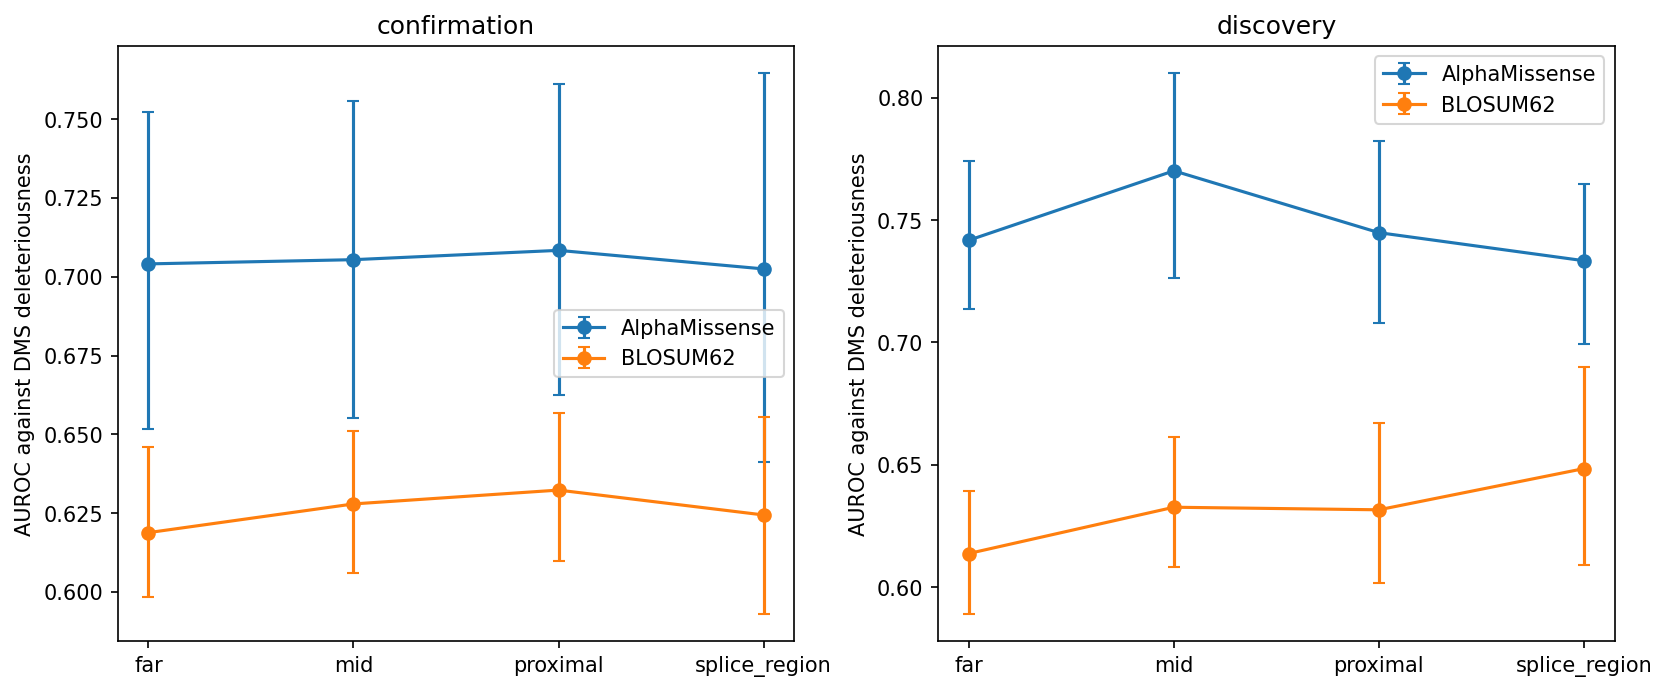

In [7]:
curves=[];contrasts=[]
for partition,g in df.groupby('protein_partition'):
    table=pd.DataFrame([dict(partition=partition,axis_level=int(level),axis_name=x.axis_name.iloc[0],**metrics(x)) for level,x in g.groupby('axis_level')]).sort_values('axis_level')
    draws=protein_bootstrap(g,2000)
    for level in table.axis_level:
        for score,column in [('am','am_auroc'),('ref','blosum_auroc')]:
            lo,hi=draws[f'{score}_auc_{level}'].quantile([.025,.975]);table.loc[table.axis_level==level,column+'_low']=lo;table.loc[table.axis_level==level,column+'_high']=hi
    for score,column in [('am','am_auroc'),('ref','blosum_auroc')]:
        lo,hi=draws['d_'+score].quantile([.025,.975]);contrasts.append({'partition':partition,'score':score,'delta':float(table[column].iloc[0]-table[column].iloc[-1]),'ci_low':lo,'ci_high':hi})
    curves.append(table)
curves=pd.concat(curves,ignore_index=True);contrasts=pd.DataFrame(contrasts)
display(curves);display(contrasts)
control=df.groupby(['protein_partition','axis_level','coarse_selection_type']).agg(rows=('mutant','size'),assays=('dms_id','nunique'),proteins=('entry_name','nunique'),median_plddt=('af2_plddt','median'),median_neff_l=('msa_neff_l','median')).reset_index();display(control)
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for ax,(partition,g) in zip(axes,curves.groupby('partition')):
    for score,label in [('am_auroc','AlphaMissense'),('blosum_auroc','BLOSUM62')]:
        y=g[score].to_numpy();ax.errorbar(g.axis_level,y,yerr=np.maximum(0,np.array([y-g[score+'_low'],g[score+'_high']-y])),marker='o',capsize=3,label=label)
    ax.set(xticks=g.axis_level,xticklabels=g.axis_name,ylabel='AUROC against DMS deleteriousness',title=partition);ax.legend()
show_figure(fig);plt.close(fig)


## 6. Result and decision

A protein-function effect at the same distance levels would support a shared protein-context explanation. Its absence limits a purely protein-function explanation of the clinical splice-distance result.


In [8]:
x=contrasts[(contrasts.partition=='confirmation') & (contrasts.score=='am')].iloc[0]
if x.ci_low>0:decision='Retain the protein-function mechanism check: AlphaMissense discrimination decreases toward internal exon boundaries in this protein-function panel, supporting a shared protein-context contribution.'
elif x.ci_high<0:decision='The protein-function panel shows the opposite directional contrast. Do not use it as support for a protein-function explanation of clinical junction-proximity degradation.'
else:decision='The protein-function endpoint contrast is inconclusive. Do not claim a confirmed distance-dependent protein-function effect.'
print(decision)


The protein-function endpoint contrast is inconclusive. Do not claim a confirmed distance-dependent protein-function effect.


In [9]:
df.to_csv(OUTPUT/'individual_dms_variants.csv.gz',index=False,compression='gzip')
curves.to_csv(OUTPUT/'curves.csv',index=False);contrasts.to_csv(OUTPUT/'contrasts.csv',index=False);control.to_csv(OUTPUT/'controls.csv',index=False)
receipt={'sources':source_receipts,'decision':decision,'rows':len(df),'assays':df.dms_id.nunique(),'proteins':df.entry_name.nunique(),'host':platform.node(),'outputs':{p.name:sha256_file(p) for p in OUTPUT.glob('*.csv*')},'elapsed_seconds':time.time()-STARTED}
(OUTPUT/'execution.json').write_text(json.dumps(receipt,indent=2)+'\n')


2801